# Solar Panel Fault Classification using KNN

**Advanced AIML Engineering Project** — complete reproducible ML backend.

> Dataset notice: the included dataset is synthetic, engineering-inspired educational data, not field measurements. Its use makes this project self-contained and reproducible. Performance on it does not establish performance on real PV systems.

This notebook covers data loading, quality checks, duplicate removal, missing values, outlier handling, categorical encoding, feature/target identification, stratified train/test separation, feature selection, KNN tuning, test evaluation, visualizations, and saving the model for Streamlit.

In [1]:
from pathlib import Path
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, matthews_corrcoef, classification_report, confusion_matrix)
from IPython.display import display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from ml_backend import (FEATURES, NUMERIC_FEATURES, CATEGORICAL_FEATURES,
    TARGET, clean_dataframe, build_pipeline, train_and_evaluate)
RANDOM_STATE=42
DATA_PATH=ROOT/'data'/'solar_pv_faults_synthetic.csv'
MODEL_PATH=ROOT/'models'/'knn_pipeline.joblib'
METADATA_PATH=ROOT/'models'/'model_metadata.json'
FIGURE_DIR=ROOT/'reports'/'figures'
print('Project root:',ROOT,'\nDataset:',DATA_PATH)

Project root: C:\Users\parth\Downloads\SolarPanelKNN_Fixed\Solar_Panel_Fault_Classification_KNN 
Dataset: C:\Users\parth\Downloads\SolarPanelKNN_Fixed\Solar_Panel_Fault_Classification_KNN\data\solar_pv_faults_synthetic.csv


## 1. Dataset justification and source
The project uses a self-generated, engineering-inspired photovoltaic fault dataset. This is permitted by the assignment, which allows a self-generated dataset. It includes six labeled operating states and numerical electrical/thermal indicators plus a categorical operating mode. The generator is provided in `src/generate_dataset.py`; the CSV is included for reproducibility. **These are synthetic observations, not measured field data.**

In [2]:
df_raw=pd.read_csv(DATA_PATH)
print('Raw shape:',df_raw.shape)
display(df_raw.head())
display(df_raw.dtypes.to_frame('dtype'))
display(df_raw['fault_label'].value_counts().to_frame('count'))

Raw shape: (6025, 12)


,irradiance_W_m2,module_temp_C,dc_voltage_V,dc_current_A,dc_power_W,fill_factor,insulation_resistance_MOhm,voltage_ripple_V,current_imbalance_pct,temperature_rise_C,operating_mode,fault_label
0,730.471708,33.680127,376.509926,8.940565,1737.585284,0.678380,10.319601,1.278630,1.966398,2.293912,Diagnostic,Normal
1,787.939797,48.222335,361.452675,9.127241,3153.335951,0.702739,10.921877,35.000000,3.756901,3.900148,MPPT,Normal
2,681.513764,36.552564,386.895909,7.845471,2432.276506,0.730633,11.330773,1.755811,2.825465,4.861642,MPPT,Normal
3,914.164760,38.748680,348.730660,7.186227,3107.446510,0.812093,9.715131,0.911890,0.351038,5.301186,MPPT,Normal
4,774.325417,46.345234,345.358786,8.232161,2947.296664,0.762028,12.178572,1.656517,3.357827,4.135158,MPPT,Normal


,dtype
irradiance_W_m2,float64
module_temp_C,float64
dc_voltage_V,float64
dc_current_A,float64
dc_power_W,float64
fill_factor,float64
insulation_resistance_MOhm,float64
voltage_ripple_V,float64
current_imbalance_pct,float64
temperature_rise_C,float64


,count
fault_label,
Normal,1009
Soiling,1005
Overheating,1005
Partial_Shading,1003
Open_Circuit,1003
Short_Circuit,1000


## 2. Data quality inspection
The raw file intentionally contains a small number of missing numeric values, outlier-like values, and exact duplicate rows so preprocessing can be demonstrated. We remove exact duplicates and rows without a target. The fitted imputer and IQR clipping transformer live inside the pipeline, so their parameters are learned only from training folds.

In [3]:
df, cleaning = clean_dataframe(df_raw)
print('Cleaning summary:',cleaning)
print('Missing values:')
display(df[FEATURES+[TARGET]].isna().sum().to_frame('missing_count'))
print('Unique classes:',sorted(df[TARGET].astype(str).unique()))

Cleaning summary: {'rows_before': 6025, 'rows_after': 6000, 'duplicates_removed': 25}
Missing values:


,missing_count
irradiance_W_m2,48
module_temp_C,48
dc_voltage_V,48
dc_current_A,48
dc_power_W,48
fill_factor,48
insulation_resistance_MOhm,48
voltage_ripple_V,48
current_imbalance_pct,48
temperature_rise_C,48


Unique classes: ['Normal', 'Open_Circuit', 'Overheating', 'Partial_Shading', 'Short_Circuit', 'Soiling']


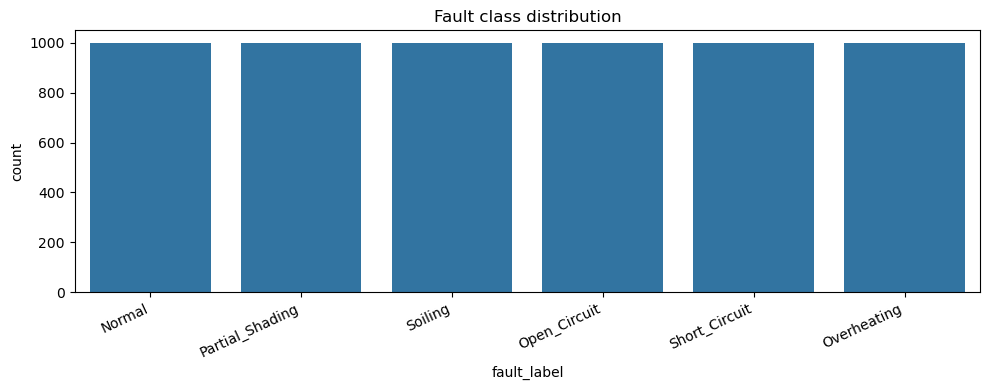

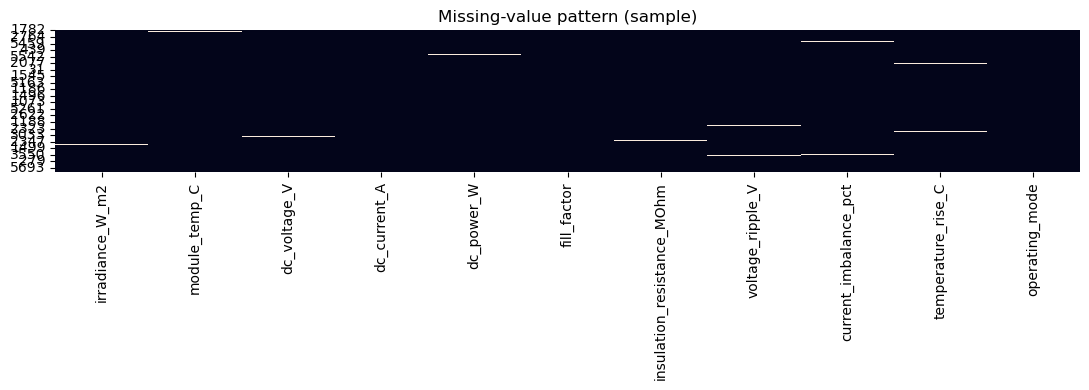

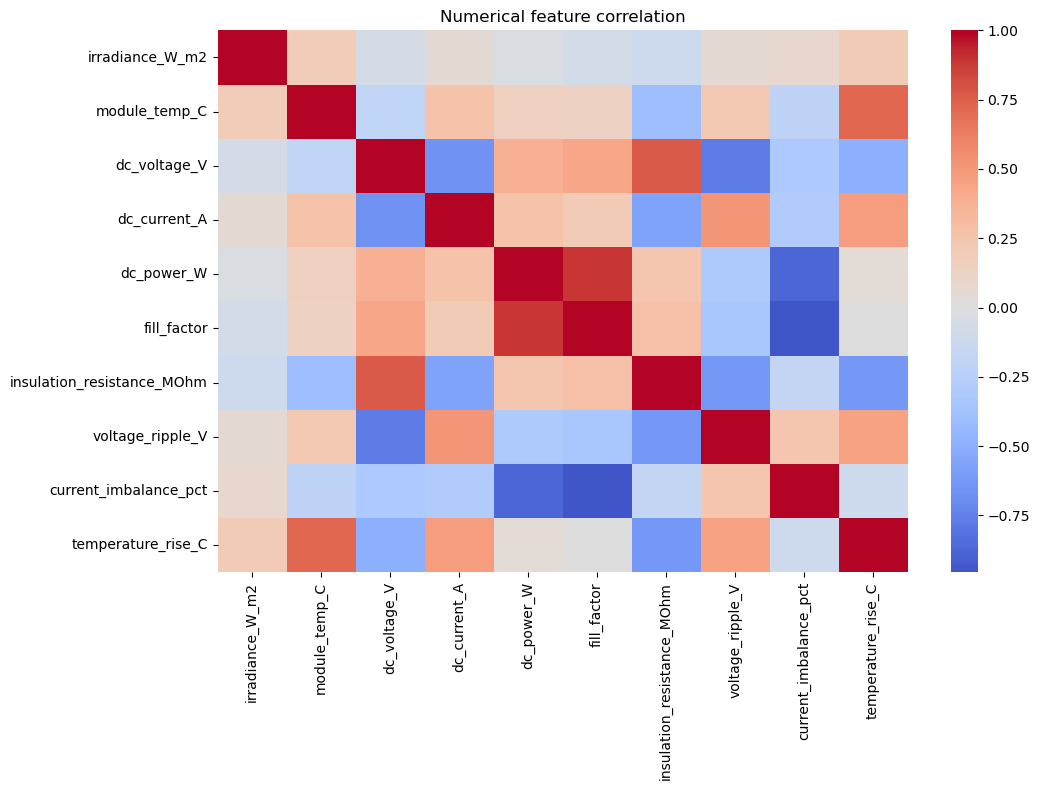

In [4]:
plt.figure(figsize=(10,4))
sns.countplot(data=df,x=TARGET,order=df[TARGET].value_counts().index)
plt.title('Fault class distribution'); plt.xticks(rotation=25,ha='right'); plt.tight_layout(); plt.show()
plt.figure(figsize=(11,4))
sns.heatmap(df[FEATURES].isna().sample(min(500,len(df)),random_state=RANDOM_STATE),cbar=False)
plt.title('Missing-value pattern (sample)'); plt.tight_layout(); plt.show()
plt.figure(figsize=(11,8)); sns.heatmap(df[NUMERIC_FEATURES].corr(),cmap='coolwarm',center=0)
plt.title('Numerical feature correlation'); plt.tight_layout(); plt.show()

## 3. Feature and target identification
Features: ten numerical electrical/thermal measurements and `operating_mode`. Target: `fault_label`. The target and any row identifiers are never included in the predictors. Exact duplicate rows are removed before splitting; all fitted transformations remain inside the ML pipeline.

In [5]:
X=df[FEATURES].copy()
y=df[TARGET].astype(str)
X[NUMERIC_FEATURES]=X[NUMERIC_FEATURES].replace([np.inf,-np.inf],np.nan)
for c in CATEGORICAL_FEATURES: X[c]=X[c].astype('object')
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,stratify=y,random_state=RANDOM_STATE)
print('Training shape:',X_train.shape,'Test shape:',X_test.shape)
display(y_train.value_counts(normalize=True).sort_index().to_frame('train proportion'))
display(y_test.value_counts(normalize=True).sort_index().to_frame('test proportion'))

Training shape: (4800, 11) Test shape: (1200, 11)


,train proportion
fault_label,
Normal,0.166667
Open_Circuit,0.166667
Overheating,0.166667
Partial_Shading,0.166667
Short_Circuit,0.166667
Soiling,0.166667


,test proportion
fault_label,
Normal,0.166667
Open_Circuit,0.166667
Overheating,0.166667
Partial_Shading,0.166667
Short_Circuit,0.166667
Soiling,0.166667


## 4. Preprocessing and KNN pipeline
Numerical variables: median imputation, IQR-based clipping, standard scaling. Categorical variable: most-frequent imputation and one-hot encoding. Feature selection: `SelectKBest(mutual_info_classif)`. Classifier: KNN. This pipeline prevents scaling/selection leakage during cross-validation.

In [6]:
pipe=build_pipeline()
print(pipe)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('outlier_clip',
                                                                   IQRClipper()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['irradiance_W_m2',
                                                   'module_temp_C',
                                                   'dc_voltage_V',
                                                   'dc_current_A', 'dc_power_W',
                                                   'fill_factor',
                                              

## 5. Hyperparameter selection
We select K and distance weighting with stratified 5-fold cross-validation on the training set, optimizing macro F1. The test set is not used to choose K. The parameter grid can take a few minutes on a standard laptop; use `run_grid_search=False` for a quick demonstration, but use grid search for final reported results.

In [7]:
param_grid={'select__k':['all',10],
            'knn__n_neighbors':[5,7,9],
            'knn__weights':['distance'],
            'knn__p':[1,2]}
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=RANDOM_STATE)
search=GridSearchCV(pipe,param_grid,scoring='f1_macro',cv=cv,n_jobs=-1,verbose=1,refit=True)
search.fit(X_train,y_train)
model=search.best_estimator_
print('Best parameters:',search.best_params_)
print('CV macro F1:',round(search.best_score_,4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'distance', 'select__k': 10}
CV macro F1: 0.9544


## 6. Test evaluation
The final model is evaluated once on the untouched 20% stratified test split. Accuracy alone can hide poor minority-class performance, so macro precision/recall/F1, balanced accuracy, and Matthews correlation coefficient are reported as well.

In [8]:
y_pred=model.predict(X_test)
metrics={'accuracy':accuracy_score(y_test,y_pred),
         'balanced_accuracy':balanced_accuracy_score(y_test,y_pred),
         'precision_macro':precision_score(y_test,y_pred,average='macro',zero_division=0),
         'recall_macro':recall_score(y_test,y_pred,average='macro',zero_division=0),
         'f1_macro':f1_score(y_test,y_pred,average='macro',zero_division=0),
         'f1_weighted':f1_score(y_test,y_pred,average='weighted',zero_division=0),
         'mcc':matthews_corrcoef(y_test,y_pred)}
display(pd.DataFrame({'metric':metrics.keys(),'score':metrics.values()}))
print(classification_report(y_test,y_pred,zero_division=0))

,metric,score
0,accuracy,0.946667
1,balanced_accuracy,0.946667
2,precision_macro,0.947740
3,recall_macro,0.946667
4,f1_macro,0.947018
5,f1_weighted,0.947018
6,mcc,0.936078


                 precision    recall  f1-score   support

         Normal       0.91      0.91      0.91       200
   Open_Circuit       1.00      1.00      1.00       200
    Overheating       1.00      1.00      1.00       200
Partial_Shading       0.95      0.91      0.93       200
  Short_Circuit       1.00      1.00      1.00       200
        Soiling       0.82      0.86      0.84       200

       accuracy                           0.95      1200
      macro avg       0.95      0.95      0.95      1200
   weighted avg       0.95      0.95      0.95      1200



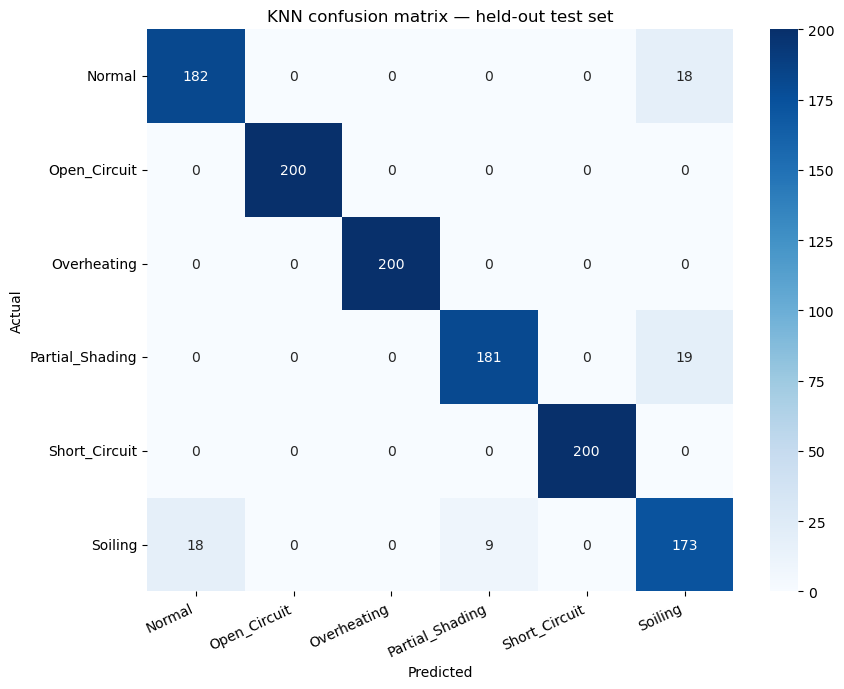

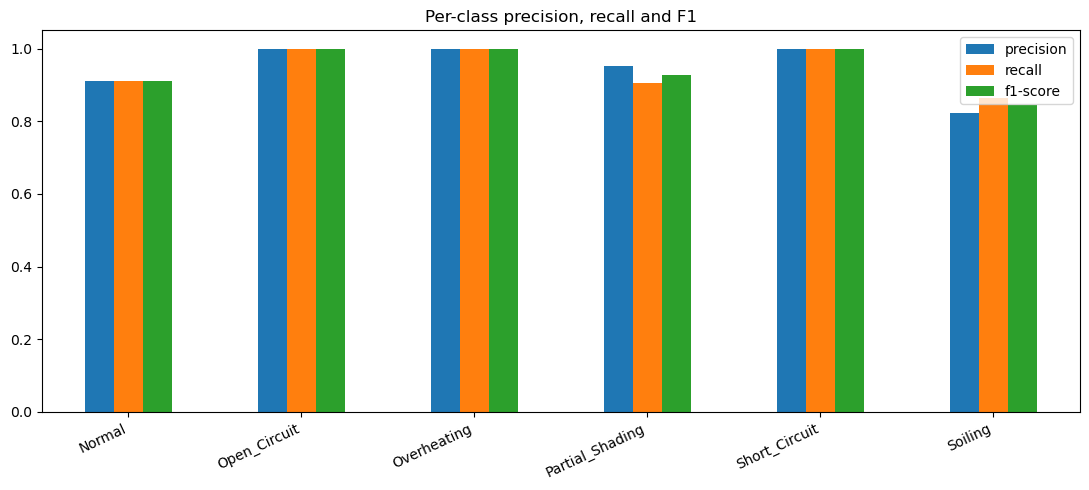

In [9]:
labels=list(model.classes_)
cm=confusion_matrix(y_test,y_pred,labels=labels)
plt.figure(figsize=(9,7)); sns.heatmap(cm,annot=True,fmt='d',xticklabels=labels,yticklabels=labels,cmap='Blues')
plt.title('KNN confusion matrix — held-out test set'); plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.xticks(rotation=25,ha='right'); plt.tight_layout(); plt.show()
report_df=pd.DataFrame(classification_report(y_test,y_pred,output_dict=True,zero_division=0)).T
report_df.loc[[x for x in labels if x in report_df.index],['precision','recall','f1-score']].plot(kind='bar',figsize=(11,5))
plt.title('Per-class precision, recall and F1'); plt.ylim(0,1.05); plt.xticks(rotation=25,ha='right'); plt.tight_layout(); plt.show()

## 7. Feature selection results

,feature,mutual_information
3,numeric__dc_current_A,1.039594
8,numeric__current_imbalance_pct,1.012322
2,numeric__dc_voltage_V,0.961742
9,numeric__temperature_rise_C,0.891319
5,numeric__fill_factor,0.844519
4,numeric__dc_power_W,0.832941
7,numeric__voltage_ripple_V,0.667643
6,numeric__insulation_resistance_MOhm,0.637846
1,numeric__module_temp_C,0.461379
0,numeric__irradiance_W_m2,0.086426


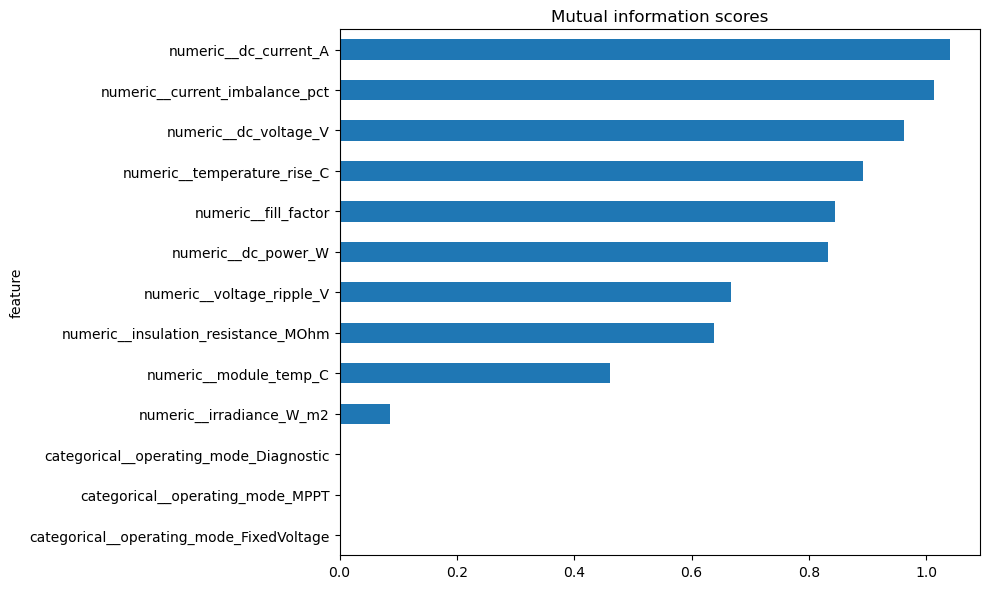

In [10]:
feature_names=model.named_steps['preprocess'].get_feature_names_out()
score_df=pd.DataFrame({'feature':feature_names,'mutual_information':model.named_steps['select'].scores_}).sort_values('mutual_information',ascending=False)
display(score_df)
score_df.head(15).sort_values('mutual_information').plot.barh(x='feature',y='mutual_information',figsize=(10,6),legend=False)
plt.title('Mutual information scores'); plt.tight_layout(); plt.show()

## 8. Save model, metrics, and plots
The saved artifact contains preprocessing, feature selection, and KNN in one pipeline. The GUI loads this same fitted pipeline.

In [11]:
import joblib
MODEL_PATH.parent.mkdir(parents=True,exist_ok=True)
joblib.dump(model,MODEL_PATH)
metadata={'project':'Solar Panel Fault Classification using KNN','dataset_type':'synthetic educational dataset; not field measurements',
          'input_features':FEATURES,'numeric_features':NUMERIC_FEATURES,'categorical_features':CATEGORICAL_FEATURES,
          'classes':[str(c) for c in model.classes_],'best_parameters':search.best_params_,
          'cv_macro_f1':float(search.best_score_),'test_metrics':{k:float(v) for k,v in metrics.items()},
          'test_size':0.20,'random_state':RANDOM_STATE,'cleaning':cleaning,
          'n_samples_after_duplicate_removal':int(len(df)),'n_train':len(X_train),'n_test':len(X_test)}
METADATA_PATH.write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('Saved model:',MODEL_PATH)
print('Saved metadata:',METADATA_PATH)

Saved model: C:\Users\parth\Downloads\SolarPanelKNN_Fixed\Solar_Panel_Fault_Classification_KNN\models\knn_pipeline.joblib
Saved metadata: C:\Users\parth\Downloads\SolarPanelKNN_Fixed\Solar_Panel_Fault_Classification_KNN\models\model_metadata.json


## 9. Classify a new input observation
Use a row with the same feature names and units as the dataset. This demonstrates inference on new user-supplied measurements.

In [12]:
example=pd.DataFrame([{'irradiance_W_m2':700,'module_temp_C':42,'dc_voltage_V':360,'dc_current_A':8,
    'dc_power_W':2800,'fill_factor':0.75,'insulation_resistance_MOhm':10,'voltage_ripple_V':1.5,
    'current_imbalance_pct':2,'temperature_rise_C':4,'operating_mode':'MPPT'}],columns=FEATURES)
print('Predicted class:',model.predict(example)[0])
if hasattr(model,'predict_proba'):
    display(pd.DataFrame({'class':model.classes_,'KNN vote probability':model.predict_proba(example)[0]}).sort_values('KNN vote probability',ascending=False))

Predicted class: Normal


,class,KNN vote probability
0,Normal,1.0
1,Open_Circuit,0.0
2,Overheating,0.0
3,Partial_Shading,0.0
4,Short_Circuit,0.0
5,Soiling,0.0
